# Анализ продаж и выполнения заказов Olist

## Цель проекта

Оценить динамику продаж маркетплейса и качество выполнения заказов,
выявить проблемные периоды и факторы, связанные со сроками доставки
и удовлетворённостью покупателей.

## Задачи

- исследовать динамику заказов, валовой стоимости и среднего чека;
- оценить долю успешно доставленных и незавершённых заказов;
- проанализировать сроки и опоздания доставки;
- проверить связь логистики с географией, категориями и отзывами;
- сформулировать выводы и ограничения анализа.

In [1]:
import duckdb
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

In [2]:
DATA_DIR = Path("../data/raw")

In [3]:
con = duckdb.connect()

In [4]:
list(DATA_DIR.glob("*.csv"))

[WindowsPath('../data/raw/olist_customers_dataset.csv'),
 WindowsPath('../data/raw/olist_geolocation_dataset.csv'),
 WindowsPath('../data/raw/olist_orders_dataset.csv'),
 WindowsPath('../data/raw/olist_order_items_dataset.csv'),
 WindowsPath('../data/raw/olist_order_payments_dataset.csv'),
 WindowsPath('../data/raw/olist_order_reviews_dataset.csv'),
 WindowsPath('../data/raw/olist_products_dataset.csv'),
 WindowsPath('../data/raw/olist_sellers_dataset.csv'),
 WindowsPath('../data/raw/product_category_name_translation.csv')]

### Загрузка и первичное знакомство с данными

In [5]:
con.sql("""
    SELECT * 
    FROM read_csv_auto('../data/raw/olist_customers_dataset.csv') 
    LIMIT 5
""").df()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,09790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,01151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,08775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


In [6]:
con.sql("""
    CREATE VIEW customers AS 
    SELECT *
    FROM read_csv_auto('../data/raw/olist_customers_dataset.csv') 
""")

In [7]:
con.sql("""
    SELECT COUNT(*)
    FROM customers
""")

┌──────────────┐
│ count_star() │
│    int64     │
├──────────────┤
│        99441 │
└──────────────┘

In [8]:
con.sql("""
    CREATE VIEW orders AS 
    SELECT * 
    FROM read_csv_auto('../data/raw/olist_orders_dataset.csv')
""")

In [9]:
con.sql("""
    SELECT * 
    FROM orders 
    LIMIT 5
""")

┌──────────────────────────────────┬──────────────────────────────────┬──────────────┬──────────────────────────┬─────────────────────┬──────────────────────────────┬───────────────────────────────┬───────────────────────────────┐
│             order_id             │           customer_id            │ order_status │ order_purchase_timestamp │  order_approved_at  │ order_delivered_carrier_date │ order_delivered_customer_date │ order_estimated_delivery_date │
│             varchar              │             varchar              │   varchar    │        timestamp         │      timestamp      │          timestamp           │           timestamp           │           timestamp           │
├──────────────────────────────────┼──────────────────────────────────┼──────────────┼──────────────────────────┼─────────────────────┼──────────────────────────────┼───────────────────────────────┼───────────────────────────────┤
│ e481f51cbdc54678b7cc49136f2d6af7 │ 9ef432eb6251297304e76186b10a928d │ deli

In [10]:
con.sql("""
    SELECT COUNT(order_id) 
    FROM orders 
""")

┌─────────────────┐
│ count(order_id) │
│      int64      │
├─────────────────┤
│           99441 │
└─────────────────┘

In [11]:
con.sql("""
    SELECT COUNT(DISTINCT order_id) 
    FROM orders 
""")

┌──────────────────────────┐
│ count(DISTINCT order_id) │
│          int64           │
├──────────────────────────┤
│                    99441 │
└──────────────────────────┘

In [12]:
con.sql("""
    SELECT order_status, COUNT(*)
    FROM orders
    GROUP BY order_status
""")

┌──────────────┬──────────────┐
│ order_status │ count_star() │
│   varchar    │    int64     │
├──────────────┼──────────────┤
│ canceled     │          625 │
│ invoiced     │          314 │
│ delivered    │        96478 │
│ created      │            5 │
│ shipped      │         1107 │
│ unavailable  │          609 │
│ approved     │            2 │
│ processing   │          301 │
└──────────────┴──────────────┘

In [13]:
con.sql("""
    CREATE VIEW order_items AS 
    SELECT * 
    FROM read_csv_auto('../data/raw/olist_order_items_dataset.csv')
""")

In [14]:
con.sql("""
    SELECT DISTINCT COUNT(order_id) 
    FROM order_items
""")

┌─────────────────┐
│ count(order_id) │
│      int64      │
├─────────────────┤
│          112650 │
└─────────────────┘

In [15]:
con.sql("""
    SELECT *
    FROM order_items
    LIMIT 5
""")

┌──────────────────────────────────┬───────────────┬──────────────────────────────────┬──────────────────────────────────┬─────────────────────┬────────┬───────────────┐
│             order_id             │ order_item_id │            product_id            │            seller_id             │ shipping_limit_date │ price  │ freight_value │
│             varchar              │     int64     │             varchar              │             varchar              │      timestamp      │ double │    double     │
├──────────────────────────────────┼───────────────┼──────────────────────────────────┼──────────────────────────────────┼─────────────────────┼────────┼───────────────┤
│ 00010242fe8c5a6d1ba2dd792cb16214 │             1 │ 4244733e06e7ecb4970a6e2683c13e61 │ 48436dade18ac8b2bce089ec2a041202 │ 2017-09-19 09:45:35 │   58.9 │         13.29 │
│ 00018f77f2f0320c557190d7a144bdd3 │             1 │ e5f2d52b802189ee658865ca93d83a8f │ dd7ddc04e1b6c2c614352b383efe2d36 │ 2017-05-03 11:05:13 │  239.

In [16]:
con.sql("""
    SELECT order_id, COUNT(*) as cnt, COUNT(DISTINCT product_id) as unique
    FROM order_items
    GROUP BY order_id
    ORDER BY cnt DESC
    LIMIT 10
""")

┌──────────────────────────────────┬───────┬────────┐
│             order_id             │  cnt  │ unique │
│             varchar              │ int64 │ int64  │
├──────────────────────────────────┼───────┼────────┤
│ 8272b63d03f5f79c56e9e4120aec44ef │    21 │      3 │
│ ab14fdcfbe524636d65ee38360e22ce8 │    20 │      1 │
│ 1b15974a0141d54e36626dca3fdc731a │    20 │      1 │
│ 9ef13efd6949e4573a18964dd1bbe7f5 │    15 │      1 │
│ 428a2f660dc84138d969ccd69a0ab6d5 │    15 │      1 │
│ 73c8ab38f07dc94389065f7eba4f297a │    14 │      1 │
│ 9bdc4d4c71aa1de4606060929dee888c │    14 │      1 │
│ 37ee401157a3a0b28c9c6d0ed8c3b24b │    13 │      1 │
│ 637617b3ffe9e2f7a2411243829226d0 │    12 │      4 │
│ 2c2a19b5703863c908512d135aa6accc │    12 │      1 │
└──────────────────────────────────┴───────┴────────┘
  10 rows                                 3 columns

### Расчёт стоимости доставленных заказов

In [17]:
con.sql("""
    SELECT DISTINCT order_item_id as id
    FROM order_items
    ORDER BY id desc
""")

┌───────┐
│  id   │
│ int64 │
├───────┤
│    21 │
│    20 │
│    19 │
│    18 │
│    17 │
│    16 │
│    15 │
│    14 │
│    13 │
│    12 │
│    11 │
│    10 │
│     9 │
│     8 │
│     7 │
│     6 │
│     5 │
│     4 │
│     3 │
│     2 │
│     1 │
└───────┘

In [18]:
con.sql("""
    SELECT order_id, order_purchase_timestamp, product_id, price, freight_value
    FROM orders 
        INNER JOIN order_items USING (order_id)
    WHERE (order_status = 'delivered')
""")

┌──────────────────────────────────┬──────────────────────────┬──────────────────────────────────┬────────┬───────────────┐
│             order_id             │ order_purchase_timestamp │            product_id            │ price  │ freight_value │
│             varchar              │        timestamp         │             varchar              │ double │    double     │
├──────────────────────────────────┼──────────────────────────┼──────────────────────────────────┼────────┼───────────────┤
│ 8426a61c687c38a2fb35080413ec9eb4 │ 2017-10-25 22:52:31      │ 110adb18eeba9a0984478ee3c9302e16 │ 179.49 │          9.45 │
│ 8426c20fc1f780e653122762baef129e │ 2017-12-16 00:58:56      │ 59ebd2c07d59483d0855b5b3d5e18728 │  27.99 │         11.85 │
│ 84270b9b2f185170b4b29b448ef3a0cc │ 2017-06-19 20:32:27      │ 777d2e438a1b645f3aec9bd57e92672c │   69.9 │         12.83 │
│ 84275d513f92f95d3e62865feeaab895 │ 2018-01-14 11:32:28      │ 2028bf1b01cafb2d2b1901fca4083222 │  56.99 │         14.15 │
│ 842785

In [19]:
con.sql("""
    SELECT order_id, order_purchase_timestamp, SUM(price + freight_value) AS order_total
    FROM orders 
        INNER JOIN order_items USING (order_id)
    WHERE (order_status = 'delivered')
    GROUP BY order_id, order_purchase_timestamp
""")

┌──────────────────────────────────┬──────────────────────────┬────────────────────┐
│             order_id             │ order_purchase_timestamp │    order_total     │
│             varchar              │        timestamp         │       double       │
├──────────────────────────────────┼──────────────────────────┼────────────────────┤
│ 842b6e7534c63c7956d72bb3f64bbecd │ 2018-02-20 10:59:58      │              25.67 │
│ 842e431b8a715723dec813ec65be3f55 │ 2017-12-05 19:10:29      │ 31.270000000000003 │
│ 843a1e7a744e7d107ee80b65be5394d2 │ 2017-03-20 19:57:40      │              39.39 │
│ 845318736fbca40fb55c8043a9871b90 │ 2018-02-18 05:05:00      │             138.89 │
│ 8482a6243b3e7ea5b3a26d6bdb586956 │ 2017-06-01 13:26:32      │              45.71 │
│ 8486f414a491ce27cbb5e501739d2d04 │ 2018-02-12 21:04:36      │              37.17 │
│ 848b0561d4bc26f57b288a5004f38683 │ 2017-11-27 19:06:12      │  604.8599999999999 │
│ 849e25f377587e96a7c12453f32f7fb2 │ 2017-02-17 08:05:08      │  

In [20]:
con.sql("""
WITH delivered_orders AS (
SELECT order_id, order_purchase_timestamp, SUM(price + freight_value) AS order_total
FROM orders 
    INNER JOIN order_items USING (order_id)
WHERE (order_status = 'delivered')
GROUP BY order_id, order_purchase_timestamp
)
    
SELECT DATE_TRUNC('month', order_purchase_timestamp) AS month, COUNT(*) AS delivered_orders, SUM(order_total) AS revenue, AVG(order_total) AS average_order_value
FROM delivered_orders
GROUP BY month
ORDER BY month ASC;

""")

┌─────────────────────┬──────────────────┬────────────────────┬─────────────────────┐
│        month        │ delivered_orders │      revenue       │ average_order_value │
│      timestamp      │      int64       │       double       │       double        │
├─────────────────────┼──────────────────┼────────────────────┼─────────────────────┤
│ 2016-09-01 00:00:00 │                1 │             143.46 │              143.46 │
│ 2016-10-01 00:00:00 │              265 │  46490.65999999999 │  175.43645283018864 │
│ 2016-12-01 00:00:00 │                1 │              19.62 │               19.62 │
│ 2017-01-01 00:00:00 │              750 │ 127482.37000000001 │  169.97649333333334 │
│ 2017-02-01 00:00:00 │             1653 │          271239.32 │  164.08912280701756 │
│ 2017-03-01 00:00:00 │             2546 │          414330.95 │  162.73800078554595 │
│ 2017-04-01 00:00:00 │             2303 │  390812.3999999999 │  169.69709075119405 │
│ 2017-05-01 00:00:00 │             3546 │  566851.399

In [21]:
con.sql("""
WITH delivered_orders AS (
SELECT order_id, order_purchase_timestamp, SUM(price + freight_value) AS order_total
FROM orders 
    INNER JOIN order_items USING (order_id)
WHERE (order_status = 'delivered')
GROUP BY order_id, order_purchase_timestamp
)
        
SELECT MIN(order_purchase_timestamp), MAX(order_purchase_timestamp)
FROM delivered_orders
""")

┌───────────────────────────────┬───────────────────────────────┐
│ min(order_purchase_timestamp) │ max(order_purchase_timestamp) │
│           timestamp           │           timestamp           │
├───────────────────────────────┼───────────────────────────────┤
│ 2016-09-15 12:16:38           │ 2018-08-29 15:00:37           │
└───────────────────────────────┴───────────────────────────────┘

In [22]:
con.sql("""
WITH all_orders AS (
SELECT order_id, order_purchase_timestamp, SUM(price + freight_value) AS order_total
FROM orders 
    INNER JOIN order_items USING (order_id)
GROUP BY order_id, order_purchase_timestamp
)
    
SELECT DATE_TRUNC('month', order_purchase_timestamp) AS month, COUNT(*) AS all_orders, SUM(order_total) AS revenue, AVG(order_total) AS average_order_value
FROM all_orders
GROUP BY month
ORDER BY month ASC;
""")

┌─────────────────────┬────────────┬────────────────────┬─────────────────────┐
│        month        │ all_orders │      revenue       │ average_order_value │
│      timestamp      │   int64    │       double       │       double        │
├─────────────────────┼────────────┼────────────────────┼─────────────────────┤
│ 2016-09-01 00:00:00 │          3 │             354.75 │              118.25 │
│ 2016-10-01 00:00:00 │        308 │           56808.84 │   184.4442857142857 │
│ 2016-12-01 00:00:00 │          1 │              19.62 │               19.62 │
│ 2017-01-01 00:00:00 │        789 │ 137188.49000000002 │   173.8764131812421 │
│ 2017-02-01 00:00:00 │       1733 │  286280.6200000001 │  165.19366416618587 │
│ 2017-03-01 00:00:00 │       2641 │ 432048.58999999997 │  163.59280196895114 │
│ 2017-04-01 00:00:00 │       2391 │          412422.24 │  172.48943538268506 │
│ 2017-05-01 00:00:00 │       3660 │  586190.9499999997 │   160.1614617486338 │
│ 2017-06-01 00:00:00 │       3217 │  50

### Месячные метрики и MoM-динамика

In [23]:
con.sql("""
WITH delivered_orders AS (
SELECT 
    order_id, 
    order_purchase_timestamp, 
    SUM(price + freight_value) AS order_total,
    SUM(price) AS order_products_total,
    SUM(freight_value) as order_freight_total
FROM orders 
    INNER JOIN order_items USING (order_id)
WHERE (order_status = 'delivered')
GROUP BY order_id, order_purchase_timestamp
)
    
SELECT 
    DATE_TRUNC('month', order_purchase_timestamp) AS month, 
     COUNT(*) AS delivered_orders, 
    SUM(order_total) AS gross_order_value, 
    AVG(order_total) AS average_order_value,
    SUM(order_products_total) AS montly_products_total,
    SUM(order_freight_total) AS monthly_freight_total,
    ROUND((monthly_freight_total * 100 / NULLIF(gross_order_value, 0)), 1) AS freight_share_pct
FROM delivered_orders
GROUP BY month
ORDER BY month ASC;
""").df()

,month,delivered_orders,gross_order_value,average_order_value,montly_products_total,monthly_freight_total,freight_share_pct
0,2016-09-01,1,143.46,143.460000,134.97,8.49,5.9
1,2016-10-01,265,46490.66,175.436453,40325.11,6165.55,13.3
2,2016-12-01,1,19.62,19.620000,10.90,8.72,44.4
3,2017-01-01,750,127482.37,169.976493,111798.36,15684.01,12.3
4,2017-02-01,1653,271239.32,164.089123,234223.40,37015.92,13.6
5,2017-03-01,2546,414330.95,162.738001,359198.85,55132.10,13.3
6,2017-04-01,2303,390812.40,169.697091,340669.68,50142.72,12.8
7,2017-05-01,3546,566851.40,159.856571,489338.25,77513.15,13.7
8,2017-06-01,3135,490050.37,156.315907,421923.37,68127.00,13.9
9,2017-07-01,3872,566299.08,146.254928,481604.52,84694.56,15.0


In [24]:
con.sql("""
WITH delivered_orders AS (
SELECT 
    order_id, 
    order_purchase_timestamp, 
    SUM(price + freight_value) AS order_total,
    SUM(price) AS order_products_total,
    SUM(freight_value) as order_freight_total
FROM orders 
    INNER JOIN order_items USING (order_id)
WHERE (order_status = 'delivered')
GROUP BY order_id, order_purchase_timestamp
),
monthly_metrics AS (
SELECT 
    DATE_TRUNC('month', order_purchase_timestamp) AS month, 
     COUNT(*) AS delivered_orders, 
    SUM(order_total) AS gross_order_value, 
    AVG(order_total) AS average_order_value,
    SUM(order_products_total) AS monthly_products_total,
    SUM(order_freight_total) AS monthly_freight_total,
    ROUND((monthly_freight_total * 100 / NULLIF(gross_order_value, 0)), 1) AS freight_share_pct
FROM delivered_orders
GROUP BY month
),
monthly_with_previous AS (
    SELECT
        month,
        gross_order_value,
        LAG(gross_order_value) OVER (ORDER BY month) AS previous_gov
    FROM monthly_metrics
    WHERE month >= DATE '2017-01-01'
        AND month <= DATE '2018-08-01'
)
        
SELECT 
    month,
    gross_order_value,
    gross_order_value - previous_gov AS mom_abs_diff,
    ROUND((gross_order_value - previous_gov) / NULLIF(previous_gov, 0) * 100, 1) AS mom_diff_pct
FROM monthly_with_previous
ORDER BY month;
""")

┌─────────────────────┬────────────────────┬─────────────────────┬──────────────┐
│        month        │ gross_order_value  │    mom_abs_diff     │ mom_diff_pct │
│      timestamp      │       double       │       double        │    double    │
├─────────────────────┼────────────────────┼─────────────────────┼──────────────┤
│ 2017-01-01 00:00:00 │ 127482.36999999998 │                NULL │         NULL │
│ 2017-02-01 00:00:00 │          271239.32 │           143756.95 │        112.8 │
│ 2017-03-01 00:00:00 │ 414330.95000000007 │  143091.63000000006 │         52.8 │
│ 2017-04-01 00:00:00 │           390812.4 │ -23518.550000000047 │         -5.7 │
│ 2017-05-01 00:00:00 │  566851.3999999999 │  176038.99999999988 │         45.0 │
│ 2017-06-01 00:00:00 │ 490050.36999999994 │  -76801.02999999997 │        -13.5 │
│ 2017-07-01 00:00:00 │  566299.0799999998 │    76248.7099999999 │         15.6 │
│ 2017-08-01 00:00:00 │  645832.3599999996 │    79533.2799999998 │         14.0 │
│ 2017-09-01 00:

Вывод: таблица показывает помесячную динамику валовой стоимости доставленных заказов (gross_order_value), включающей стоимость товаров и доставки, а также её абсолютное и процентное изменение относительно предыдущего месяца. Динамика неравномерна: встречаются как месяцы роста, так и месяцы снижения.
Основной период анализа начинается с января 2017 года. Данные за сентябрь–декабрь 2016 года фрагментарны: в сентябре и декабре присутствует только по одному доставленному заказу, а данные за ноябрь отсутствуют.
Август 2018 года включён в таблицу, однако требует осторожной интерпретации: последний доставленный заказ по дате оформления относится к 29 августа, хотя в исходной таблице существуют заказы от 30–31 августа. Поэтому августовские показатели доставленных заказов могут быть занижены.

### Анализ статусов заказов

In [25]:
con.sql("""
WITH monthly_order_status AS (
SELECT 
    DATE_TRUNC('month', order_purchase_timestamp) AS month, 
    order_status,
    COUNT(*) AS status_orders_count,
    SUM(COUNT(*)) OVER (PARTITION BY month) AS all_orders_count,
    ROUND(status_orders_count / (all_orders_count / 100), 1) AS share_pct,
    MIN(order_purchase_timestamp),
    MAX(order_purchase_timestamp)
FROM orders
GROUP BY month, order_status

)
        
SELECT 
    *
FROM monthly_order_status
ORDER BY month ASC
""")

┌─────────────────────┬──────────────┬─────────────────────┬──────────────────┬───────────┬───────────────────────────────┬───────────────────────────────┐
│        month        │ order_status │ status_orders_count │ all_orders_count │ share_pct │ min(order_purchase_timestamp) │ max(order_purchase_timestamp) │
│      timestamp      │   varchar    │        int64        │      int128      │  double   │           timestamp           │           timestamp           │
├─────────────────────┼──────────────┼─────────────────────┼──────────────────┼───────────┼───────────────────────────────┼───────────────────────────────┤
│ 2016-09-01 00:00:00 │ delivered    │                   1 │                4 │      25.0 │ 2016-09-15 12:16:38           │ 2016-09-15 12:16:38           │
│ 2016-09-01 00:00:00 │ shipped      │                   1 │                4 │      25.0 │ 2016-09-04 21:15:19           │ 2016-09-04 21:15:19           │
│ 2016-09-01 00:00:00 │ canceled     │                   2 │    

In [26]:
con.sql("""
SELECT
    order_status AS status,
    COUNT(*) AS orders_count,
    COUNT(*) FILTER (WHERE order_delivered_carrier_date IS NULL) AS missing_carrier_date,
    COUNT(*) FILTER (WHERE order_delivered_customer_date IS NULL) AS missing_customer_date,
    COUNT(*) FILTER (WHERE order_approved_at IS NOT NULL AND order_delivered_carrier_date IS NULL) AS stuck_before_shipping,
    COUNT(*) FILTER (WHERE order_approved_at IS NOT NULL AND order_delivered_customer_date IS NULL AND order_delivered_carrier_date IS NOT NULL) AS stuck_in_delivery
FROM orders
WHERE order_status IN ('processing', 'invoiced', 'shipped')
  AND order_purchase_timestamp < DATE '2017-12-01'
GROUP BY status
""")

┌────────────┬──────────────┬──────────────────────┬───────────────────────┬───────────────────────┬───────────────────┐
│   status   │ orders_count │ missing_carrier_date │ missing_customer_date │ stuck_before_shipping │ stuck_in_delivery │
│  varchar   │    int64     │        int64         │         int64         │         int64         │       int64       │
├────────────┼──────────────┼──────────────────────┼───────────────────────┼───────────────────────┼───────────────────┤
│ processing │          207 │                  207 │                   207 │                   207 │                 0 │
│ shipped    │          482 │                    0 │                   482 │                     0 │               482 │
│ invoiced   │          180 │                  180 │                   180 │                   180 │                 0 │
└────────────┴──────────────┴──────────────────────┴───────────────────────┴───────────────────────┴───────────────────┘

In [27]:
con.sql("""
WITH delivery_features AS (
SELECT 
    order_id, 
    order_delivered_customer_date - order_purchase_timestamp AS delivery_time,
    CAST(order_delivered_customer_date AS DATE) - CAST(order_estimated_delivery_date AS DATE) AS delay_days,
    delay_days > 0 AS is_late
FROM orders     
WHERE (order_status = 'delivered')
),
late_count AS (
SELECT 
    is_late, 
    COUNT(*) as orders_count,
    SUM(COUNT(*)) OVER () AS total_cnt,
    ROUND(orders_count * 100.0 / total_cnt, 2) AS late_pct
FROM delivery_features
WHERE is_late IS NOT NULL
GROUP BY is_late
)

SELECT * FROM late_count
""")

┌─────────┬──────────────┬───────────┬──────────┐
│ is_late │ orders_count │ total_cnt │ late_pct │
│ boolean │    int64     │  int128   │  double  │
├─────────┼──────────────┼───────────┼──────────┤
│ false   │        89936 │     96470 │    93.23 │
│ true    │         6534 │     96470 │     6.77 │
└─────────┴──────────────┴───────────┴──────────┘

#### Среди заказов с известной датой доставки, **6.77%** заказов были доставлены позже обещанной календарной даты

### Связь опозданий и ревью

In [28]:
con.sql("""
    CREATE VIEW reviews AS 
    SELECT *
    FROM read_csv_auto('../data/raw/olist_order_reviews_dataset.csv') 
""")

In [29]:
con.sql("""
SELECT 
    COUNT(DISTINCT review_id), 
    COUNT(DISTINCT order_id), 
    COUNT(*)
FROM reviews
""")

┌───────────────────────────┬──────────────────────────┬──────────────┐
│ count(DISTINCT review_id) │ count(DISTINCT order_id) │ count_star() │
│           int64           │          int64           │    int64     │
├───────────────────────────┼──────────────────────────┼──────────────┤
│                     98410 │                    98673 │        99224 │
└───────────────────────────┴──────────────────────────┴──────────────┘

In [30]:
con.sql("""
SELECT order_id, COUNT(*) AS reviews_count
FROM reviews
GROUP BY order_id
HAVING COUNT(*) > 1
ORDER BY reviews_count DESC;
""")

┌──────────────────────────────────┬───────────────┐
│             order_id             │ reviews_count │
│             varchar              │     int64     │
├──────────────────────────────────┼───────────────┤
│ 03c939fd7fd3b38f8485a0f95798f1f6 │             3 │
│ c88b1d1b157a9999ce368f218a407141 │             3 │
│ 8e17072ec97ce29f0e1f111e598b0c85 │             3 │
│ df56136b8031ecd28e200bb18e6ddb2e │             3 │
│ d78c16f09da03410837a551a09a4bf64 │             2 │
│ ebe8e5e35f85b19e3b8132a054bbf523 │             2 │
│ ace3b21c5c57456d2e2215452829073b │             2 │
│ 56fcb6d24acb1b94dd4492f663187b69 │             2 │
│ 6b9c8c185575db6251ea1e2c699cddd5 │             2 │
│ acbaf2e843c77c9749c79030163c8b81 │             2 │
│                ·                 │             · │
│                ·                 │             · │
│                ·                 │             · │
│ 0ee24d5ae95ccf0552a2ef03dfadb924 │             2 │
│ 3cf387bb14e9db171ccbb9b87ea607bb │          

In [31]:
con.sql("""
SELECT
    review_id,
    COUNT(*) AS rows_count,
    COUNT(DISTINCT order_id) AS orders_count
FROM reviews
GROUP BY review_id
HAVING COUNT(DISTINCT order_id) > 1
ORDER BY orders_count DESC;
""")

┌──────────────────────────────────┬────────────┬──────────────┐
│            review_id             │ rows_count │ orders_count │
│             varchar              │   int64    │    int64     │
├──────────────────────────────────┼────────────┼──────────────┤
│ 0c76e7a547a531e7bf9f0b99cba071c1 │          3 │            3 │
│ ddc52555ca27b0fe67d5255147682d2d │          3 │            3 │
│ abbfacb2964f74f6487c9c10ac46daa6 │          3 │            3 │
│ 2d6ac45f859465b5c185274a1c929637 │          3 │            3 │
│ 70509c441d994fa03d6c1457930c9024 │          3 │            3 │
│ 3415c9f764e478409e8e0660ae816dd2 │          3 │            3 │
│ 4219a80ab469e3fc9901437b73da3f75 │          3 │            3 │
│ 69a1068c3128a14994e3e422e4539e04 │          3 │            3 │
│ 9e25d6e3025e9b9a0fc7f03588d33e2b │          3 │            3 │
│ 08528f70f579f0c830189efc523d2182 │          3 │            3 │
│                ·                 │          · │            · │
│                ·       

In [32]:
con.sql("""
    SELECT *
    FROM reviews
    WHERE (review_id = '4d0e6dd087008d1f992d25ef6e1f619f')
""")

┌──────────────────────────────────┬──────────────────────────────────┬──────────────┬──────────────────────┬────────────────────────┬──────────────────────┬─────────────────────────┐
│            review_id             │             order_id             │ review_score │ review_comment_title │ review_comment_message │ review_creation_date │ review_answer_timestamp │
│             varchar              │             varchar              │    int64     │       varchar        │        varchar         │      timestamp       │        timestamp        │
├──────────────────────────────────┼──────────────────────────────────┼──────────────┼──────────────────────┼────────────────────────┼──────────────────────┼─────────────────────────┤
│ 4d0e6dd087008d1f992d25ef6e1f619f │ d415e95816c2f3a2a34e06cd519157cc │            4 │ NULL                 │ NULL                   │ 2018-06-12 00:00:00  │ 2018-06-17 23:48:04     │
│ 4d0e6dd087008d1f992d25ef6e1f619f │ cd0343141ac675cd40fab2c7fd2e99cc │         

In [33]:
con.sql("""
SELECT 
    review_score,
    COUNT(*) as review_cnt,
    SUM(COUNT(*)) OVER () AS total_reviews,
    -- AVG(review_score) OVER (),
    ROUND(review_cnt * 100 / total_reviews, 2) AS review_dist
FROM orders 
    INNER JOIN reviews USING (order_id)
GROUP BY review_score
ORDER BY review_score
""")

┌──────────────┬────────────┬───────────────┬─────────────┐
│ review_score │ review_cnt │ total_reviews │ review_dist │
│    int64     │   int64    │    int128     │   double    │
├──────────────┼────────────┼───────────────┼─────────────┤
│            1 │      11424 │         99224 │       11.51 │
│            2 │       3151 │         99224 │        3.18 │
│            3 │       8179 │         99224 │        8.24 │
│            4 │      19142 │         99224 │       19.29 │
│            5 │      57328 │         99224 │       57.78 │
└──────────────┴────────────┴───────────────┴─────────────┘

In [34]:
con.sql("""
WITH clean_reviews AS (
SELECT COUNT(*)
FROM reviews
GROUP BY review_id
HAVING COUNT(DISTINCT order_id) = 1
)
SELECT * FROM clean_reviews
""")

┌────────────────────────┐
│      count_star()      │
│         int64          │
├────────────────────────┤
│                      1 │
│                      1 │
│                      1 │
│                      1 │
│                      1 │
│                      1 │
│                      1 │
│                      1 │
│                      1 │
│                      1 │
│                      · │
│                      · │
│                      · │
│                      1 │
│                      1 │
│                      1 │
│                      1 │
│                      1 │
│                      1 │
│                      1 │
│                      1 │
│                      1 │
│                      1 │
└────────────────────────┘
          ? rows        
  (>9999 rows, 20 shown) 

In [35]:
con.sql("""
WITH valid_review_ids AS (
    SELECT
        review_id
    FROM reviews
    GROUP BY review_id
    HAVING COUNT(DISTINCT order_id) = 1
),
valid_reviews AS (
SELECT reviews.*
FROM reviews    
    JOIN valid_review_ids USING (review_id)  
),
ranked_reviews AS (
SELECT 
    *,
    ROW_NUMBER() OVER (PARTITION BY order_id ORDER BY review_answer_timestamp DESC, review_id) as review_rank
    FROM valid_reviews
),
clean_reviews AS (
    SELECT *
    FROM ranked_reviews
    WHERE review_rank = 1
), delivery_features AS (
SELECT 
    order_id, 
    order_delivered_customer_date - order_purchase_timestamp AS delivery_time,
    CAST(order_delivered_customer_date AS DATE) - CAST(order_estimated_delivery_date AS DATE) AS delay_days,
    delay_days > 0 AS is_late
FROM orders     
WHERE (order_status = 'delivered') AND is_late IS NOT NULL
)

SELECT 
    review_score, 
    is_late, 
    COUNT(*) as orders_count,
    SUM(COUNT(*)) OVER (PARTITION BY is_late) AS total_cnt,
    ROUND(orders_count * 100 / total_cnt, 2) AS share_within_delivery_group
    FROM delivery_features 
        JOIN clean_reviews USING (order_id)
    GROUP BY is_late, review_score
    ORDER BY is_late DESC, review_score DESC; 
""").df()

,review_score,is_late,orders_count,total_cnt,share_within_delivery_group
0,5,True,1043,6307.0,16.54
1,4,True,642,6307.0,10.18
2,3,True,689,6307.0,10.92
3,2,True,545,6307.0,8.64
4,1,True,3388,6307.0,53.72
5,5,False,55169,88467.0,62.36
6,4,False,18078,88467.0,20.43
7,3,False,7115,88467.0,8.04
8,2,False,2328,88467.0,2.63
9,1,False,5777,88467.0,6.53


In [36]:
con.sql("""
WITH valid_review_ids AS (
    SELECT
        review_id
    FROM reviews
    GROUP BY review_id
    HAVING COUNT(DISTINCT order_id) = 1
),
valid_reviews AS (
SELECT reviews.*
FROM reviews    
    JOIN valid_review_ids USING (review_id)  
),
ranked_reviews AS (
SELECT 
    *,
    ROW_NUMBER() OVER (PARTITION BY order_id ORDER BY review_answer_timestamp DESC, review_id) as review_rank
    FROM valid_reviews
)
SELECT * FROM ranked_reviews
""")

┌──────────────────────────────────┬──────────────────────────────────┬──────────────┬──────────────────────┬──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────┬──────────────────────┬─────────────────────────┬─────────────┐
│            review_id             │             order_id             │ review_score │ review_comment_title │                                                                                          review_comment_message                                                                                          │ review_creation_date │ review_answer_timestamp │ review_rank │
│             varchar              │             varchar              │    int64     │       varchar        │                                                                                                 varchar                                   

In [37]:
con.sql("""
WITH valid_review_ids AS (
    SELECT
        review_id
    FROM reviews
    GROUP BY review_id
    HAVING COUNT(DISTINCT order_id) = 1
),
        
valid_reviews AS (
SELECT reviews.*
FROM reviews    
    JOIN valid_review_ids USING (review_id)  
),
        
ranked_reviews AS (
SELECT 
    *,
    ROW_NUMBER() OVER (PARTITION BY order_id ORDER BY review_answer_timestamp DESC, review_id) as review_rank
    FROM valid_reviews
),
        
clean_reviews AS (
    SELECT *
    FROM ranked_reviews
    WHERE review_rank = 1
), 

delivery_features AS (
SELECT 
    order_id, 
    order_delivered_customer_date - order_purchase_timestamp AS delivery_time,
    CAST(order_delivered_customer_date AS DATE) - CAST(order_estimated_delivery_date AS DATE) AS delay_days,
    delay_days > 0 AS is_late
FROM orders     
WHERE (order_status = 'delivered') AND is_late IS NOT NULL
),
        
bucketed_orders AS (
SELECT 
    df.order_id,
    df.delay_days,
    cr.review_score,
    CASE 
        WHEN df.delay_days = 1 THEN '1 day'
        WHEN df.delay_days BETWEEN 2 AND 3 THEN '2-3 days'
        WHEN df.delay_days BETWEEN 4 AND 7 THEN '4-7 days'
        WHEN df.delay_days BETWEEN 8 AND 14 THEN '8-14 days'
        WHEN df.delay_days BETWEEN 15 AND 30 THEN '15-30 days'
        ELSE '31+ days'
    END AS delay_bucket 
FROM delivery_features AS df
    INNER JOIN clean_reviews AS cr USING (order_id)
WHERE df.is_late = true
)
    
SELECT
    delay_bucket,
    COUNT(*) AS orders_count,
    ROUND(AVG(review_score), 2) AS average_review_score
FROM bucketed_orders
GROUP BY delay_bucket
ORDER BY MIN(delay_days)
""").df()

,delay_bucket,orders_count,average_review_score
0,1 day,813,3.74
1,2-3 days,1020,2.94
2,4-7 days,1731,2.11
3,8-14 days,1431,1.67
4,15-30 days,990,1.61
5,31+ days,322,2.05


#### Вывод: с увеличением длительности задержки средняя оценка заказа в целом снижается. Для заказов, доставленных вовремя, оценка составялет 4.29 балла, при задержке в один день - 3.74, а при задержке 15-30 дней - 1.61. Наиболее заметное снижение наблюдается за первую неделю опоздания: средняя оценка падает с 3.74 при задержке на один день до 2.11 при задержке на 4-7 дней.

#### На всём диапазоне зависимость не является строго монотонной: для задержке свыше 30 дней средняя оценка повышается до 2.05. Это может быть связано с составом группы и широким интервалом 31+, поэтому результат не следует интерпретировать как улучшение клиентского опыта при экстремальных задержках

### Связь логистики и географии

In [38]:
con.sql("""
SELECT COUNT(DISTINCT customer_id) 
FROM customers
""")

┌─────────────────────────────┐
│ count(DISTINCT customer_id) │
│            int64            │
├─────────────────────────────┤
│                       99441 │
└─────────────────────────────┘

In [39]:
con.sql("""
WITH delivery_features AS (
SELECT 
    order_id, 
    EXTRACT(
        EPOCH FROM (
            order_delivered_customer_date - order_purchase_timestamp
        )
    ) / 86400.0 AS delivery_days,
    CAST(order_delivered_customer_date AS DATE) - CAST(order_estimated_delivery_date AS DATE) AS delay_days,
    delay_days > 0 AS is_late
FROM orders     
WHERE (order_status = 'delivered') AND is_late IS NOT NULL
)
        
SELECT 
    customer_state,
    COUNT(*) FILTER (WHERE is_late = true) as late_orders,
    COUNT(*) AS delivered_orders,
    late_orders / NULLIF(delivered_orders, 0) * 100 late_share_pct,
    ROUND(AVG(delivery_days), 2) average_delivery_time
FROM delivery_features df
    JOIN orders USING (order_id)
    JOIN customers USING (customer_id)
GROUP BY customer_state
ORDER BY delivered_orders DESC, late_share_pct DESC;
""")

┌────────────────┬─────────────┬──────────────────┬────────────────────┬───────────────────────┐
│ customer_state │ late_orders │ delivered_orders │   late_share_pct   │ average_delivery_time │
│    varchar     │    int64    │      int64       │       double       │        double         │
├────────────────┼─────────────┼──────────────────┼────────────────────┼───────────────────────┤
│ SP             │        1820 │            40494 │  4.494493011310317 │                  8.76 │
│ RJ             │        1495 │            12350 │ 12.105263157894736 │                 15.31 │
│ MG             │         519 │            11354 │  4.571076272679233 │                 12.01 │
│ RS             │         325 │             5344 │  6.081586826347305 │                  15.3 │
│ PR             │         199 │             4923 │  4.042250660166565 │                 11.99 │
│ SC             │         291 │             3546 │  8.206429780033842 │                 14.95 │
│ BA             │         396

In [40]:
state_metrics = con.sql("""
WITH delivery_features AS (
SELECT 
    order_id, 
    EXTRACT(
        EPOCH FROM (
            order_delivered_customer_date - order_purchase_timestamp
        )
    ) / 86400.0 AS delivery_days,
    CAST(order_delivered_customer_date AS DATE) - CAST(order_estimated_delivery_date AS DATE) AS delay_days,
    delay_days > 0 AS is_late
FROM orders     
WHERE (order_status = 'delivered') AND is_late IS NOT NULL
)
        
SELECT 
    customer_state,
    COUNT(*) FILTER (WHERE is_late = true) as late_orders,
    COUNT(*) AS delivered_orders,
    late_orders / NULLIF(delivered_orders, 0) * 100 late_share_pct,
    ROUND(AVG(delivery_days), 2) average_delivery_time
FROM delivery_features df
    JOIN orders USING (order_id)
    JOIN customers USING (customer_id)
GROUP BY customer_state
ORDER BY delivered_orders DESC, late_share_pct DESC;
""").df()

In [41]:
plot_data = (
    state_metrics
    .query("delivered_orders >= 500")
    .sort_values("late_share_pct")
    .copy()
)

plot_data["state_label"] = (
    plot_data["customer_state"]
    + " (n="
    + plot_data["delivered_orders"].astype(str)
    + ")"
)

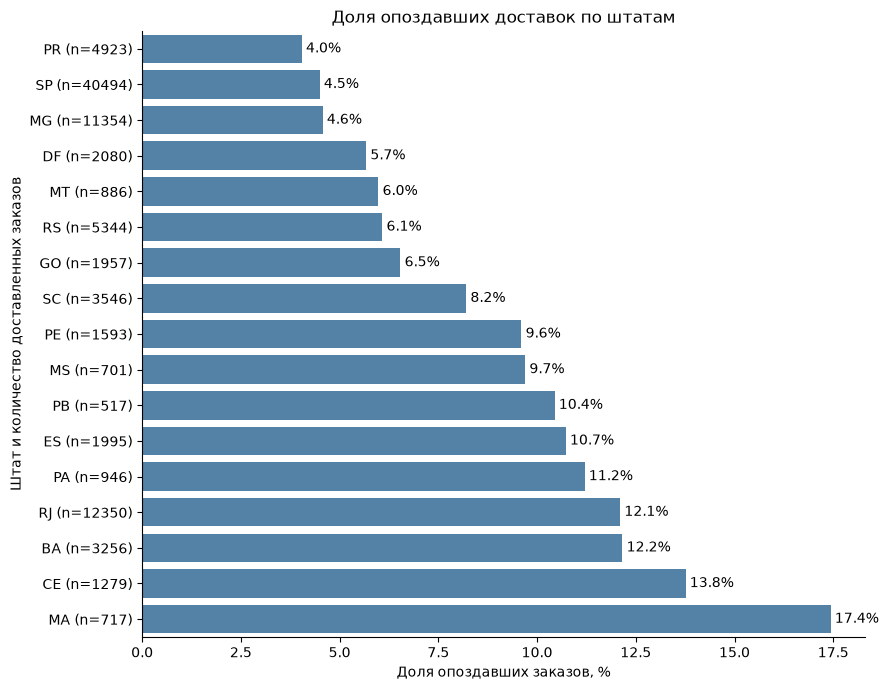

In [42]:
fig, ax = plt.subplots(figsize=(9, 7))

sns.barplot(
    data=plot_data,
    x="late_share_pct",
    y="state_label",
    color="steelblue",
    ax=ax
)

ax.bar_label(
    ax.containers[0],
    fmt="%.1f%%",
    padding=3
)

ax.set(
    title="Доля опоздавших доставок по штатам",
    xlabel="Доля опоздавших заказов, %",
    ylabel="Штат и количество доставленных заказов"
)

sns.despine()
plt.tight_layout()
plt.show()

### Связь логистики и категорий товаров

In [43]:
con.sql("""
    CREATE VIEW products AS 
    SELECT *
    FROM read_csv_auto('../data/raw/olist_products_dataset.csv') 
""")

In [44]:
con.sql("""
    CREATE VIEW translation AS 
    SELECT *
    FROM read_csv_auto('../data/raw/product_category_name_translation.csv') 
""")

In [45]:
con.sql("""
WITH order_category_counts AS (
SELECT 
    order_id,
    COUNT(DISTINCT product_category_name) as categories_count,
FROM order_items
    JOIN products USING (product_id)
GROUP BY order_id
)
SELECT 
    CASE 
        WHEN categories_count = 1 THEN 'one_category' 
        WHEN categories_count > 1 THEN 'few_categories' 
        ELSE 'unknown_category'
    END AS category_group,
    COUNT(*) AS orders_count
FROM order_category_counts
GROUP BY category_group
""")

┌──────────────────┬──────────────┐
│  category_group  │ orders_count │
│     varchar      │    int64     │
├──────────────────┼──────────────┤
│ one_category     │        96550 │
│ unknown_category │         1389 │
│ few_categories   │          727 │
└──────────────────┴──────────────┘

In [46]:
con.sql("""
WITH order_categories AS (
SELECT DISTINCT 
    order_id, 
    COALESCE(
        t.product_category_name_english,
        p.product_category_name) as category
FROM order_items oi 
    JOIN products p USING (product_id)
    LEFT JOIN translation t ON p.product_category_name = t.product_category_name
),
delivery_features AS (
SELECT 
    order_id, 
    EXTRACT(
        EPOCH FROM (
            order_delivered_customer_date - order_purchase_timestamp
        )
    ) / 86400.0 AS delivery_days,
    CAST(order_delivered_customer_date AS DATE) - CAST(order_estimated_delivery_date AS DATE) AS delay_days,
    delay_days > 0 AS is_late
FROM orders     
WHERE (order_status = 'delivered') AND is_late IS NOT NULL
)
        
SELECT 
    category, 
    COUNT(*) AS delivered_orders,
    COUNT(*) FILTER (WHERE is_late = TRUE) AS late_orders,
    ROUND((late_orders / delivered_orders) * 100, 2) AS late_share_pct,
    ROUND(AVG(delivery_days), 2) AS average_delivery_days
FROM order_categories oc
    JOIN delivery_features USING (order_id)
WHERE (category IS NOT NULL)
GROUP BY category
HAVING (delivered_orders > 500)
ORDER BY late_share_pct DESC, delivered_orders DESC;
""")

┌─────────────────────────────────┬──────────────────┬─────────────┬────────────────┬───────────────────────┐
│            category             │ delivered_orders │ late_orders │ late_share_pct │ average_delivery_days │
│             varchar             │      int64       │    int64    │     double     │        double         │
├─────────────────────────────────┼──────────────────┼─────────────┼────────────────┼───────────────────────┤
│ baby                            │             2809 │         226 │           8.05 │                 12.68 │
│ office_furniture                │             1254 │         101 │           8.05 │                 20.64 │
│ electronics                     │             2517 │         192 │           7.63 │                 12.92 │
│ musical_instruments             │              611 │          46 │           7.53 │                 13.07 │
│ health_beauty                   │             8647 │         649 │           7.51 │                 12.08 │
│ bed_bath

#### Среди массовых категорий не обнаружено экстремально высокой доли опозданий. Категории bebes, eletronicos, beleza_saude, cama_mesa_banho и relogios_presentes умеренно превышают общий уровень задержек. Наиболее заметно выделяется moveis_escritorio: помимо доли опозданий выше среднего, эта категория имеет средний срок доставки 20,64 дня, что существенно выше большинства массовых категорий.
#### Наблюдаемые различия не позволяют считать категорию непосредственной причиной задержек: они могут быть связаны с габаритами товаров, расположением продавцов и покупателей или особенностями обработки заказов.

## Выводы:

### Опоздания и отзывы:
**Наблюдение:** с увеличением длительности задержки доставки средняя оценка заказа в целом снижается. Для заказов, доставленных вовремя, оценка составялет 4,29 балла, при задержке в один день - 3,74, а при задержке 15-30 дней - 1,61.

**Возможное объяснение:** задержка доставки может ухудшать клиентский опыт и быть одной из причин более низкой оценки товара

**Ограничение:** на оценку может влиять не только задержка доставки, но и, например, качество товара

**Рекомендация:** рекомендуется в первую очередь выяснить основные причины задержек доставки, поскольку уже в течение первой недели опоздания средняя оценка снижается с 4,29 для своевременно доставленных заказов до 2,11 для заказов с задержкой 4–7 дней.

### География: 
**Наблюдение:** штат SP, в который было доставлено наибольшее количество заказов, имеет долю опоздавших доставленных заказов около 4,5%, тогда как штаты RJ, BA, CE, MA имеют заметно более высокую долю опозданий, например для RJ доля заказов, доставленных не в срок, составила 12,1%

**Возможное объяснение:** различия могут быть связаны с расстоянием между продавцами и покупателями, распределением продавцов по регионам и особенностями региональной логистической инфраструктуры.

**Ограничение:** нельзя утверждать точную причину задержек логистики из имеющейся статистики.

**Рекомендация:** в первую очередь рекомендуется подробнее исследовать доставки в штат RJ, проверив связь опозданий с расстоянием между продавцами и покупателями, поскольку штат сочетает большой объём заказов и высокую долю доставок с нарушением обещанного срока.

### Анализ связи географии и опозданий. 
Вопрос: почему RJ имеет долю опозданий доставок почти в 2.7 раза выше, чем штата SP?

In [47]:
con.sql("""
    CREATE VIEW sellers AS 
    SELECT *
    FROM read_csv_auto('../data/raw/olist_sellers_dataset.csv') 
""")
con.sql("""
    CREATE VIEW geolocation AS 
    SELECT *
    FROM read_csv_auto('../data/raw/olist_geolocation_dataset.csv') 
""")

In [48]:
con.sql("""
SELECT 
    geolocation_zip_code_prefix, 
    COUNT(*) as sum_count,
    COUNT(DISTINCT geolocation_lat)
FROM geolocation
GROUP BY geolocation_zip_code_prefix
ORDER BY geolocation_zip_code_prefix ASC;
""")

┌─────────────────────────────┬───────────┬─────────────────────────────────┐
│ geolocation_zip_code_prefix │ sum_count │ count(DISTINCT geolocation_lat) │
│           varchar           │   int64   │              int64              │
├─────────────────────────────┼───────────┼─────────────────────────────────┤
│ 01001                       │        26 │                              10 │
│ 01002                       │        13 │                               6 │
│ 01003                       │        17 │                              10 │
│ 01004                       │        22 │                              14 │
│ 01005                       │        25 │                              11 │
│ 01006                       │         9 │                               7 │
│ 01007                       │        26 │                              15 │
│ 01008                       │        16 │                              12 │
│ 01009                       │        41 │                     

In [49]:
con.sql("""
SELECT 
    COUNT(*), 
    COUNT(DISTINCT geolocation_zip_code_prefix)
FROM geolocation
""")

┌──────────────┬─────────────────────────────────────────────┐
│ count_star() │ count(DISTINCT geolocation_zip_code_prefix) │
│    int64     │                    int64                    │
├──────────────┼─────────────────────────────────────────────┤
│      1000163 │                                       19015 │
└──────────────┴─────────────────────────────────────────────┘

In [50]:
con.sql("""
WITH zip_coordinates AS (
    SELECT 
        geolocation_zip_code_prefix AS zip_prefix,
        MIN(geolocation_lat) AS min_lat,
        MAX(geolocation_lat) AS max_lat,
        MIN(geolocation_lng) AS min_lng,
        MAX(geolocation_lng) AS max_lng,
        MEDIAN(geolocation_lat) AS median_lat,
        MEDIAN(geolocation_lng) AS median_lng,
        AVG(geolocation_lat) AS avg_lat,
        AVG(geolocation_lng) AS avg_lng,
        (max_lat - min_lat) AS lat_diff,
        (max_lng - min_lng) AS lng_diff,
        ABS(avg_lat - median_lat),
        ABS(avg_lng - median_lng),
    FROM geolocation
    GROUP BY geolocation_zip_code_prefix
)

SELECT 
    *
FROM zip_coordinates
ORDER BY lat_diff DESC, lng_diff DESC;
""")

┌────────────┬─────────────────────┬─────────────────────┬─────────────────────┬─────────────────────┬─────────────────────┬─────────────────────┬──────────────────────┬─────────────────────┬──────────────────────┬───────────────────────┬─────────────────────────────┬─────────────────────────────┐
│ zip_prefix │       min_lat       │       max_lat       │       min_lng       │       max_lng       │     median_lat      │     median_lng      │       avg_lat        │       avg_lng       │       lat_diff       │       lng_diff        │ abs((avg_lat - median_lat)) │ abs((avg_lng - median_lng)) │
│  varchar   │       double        │       double        │       double        │       double        │       double        │       double        │        double        │       double        │        double        │        double         │           double            │           double            │
├────────────┼─────────────────────┼─────────────────────┼─────────────────────┼─────────────────────┼─

Таблица геолокации содержит несколько координат для одного zip-префикса и отдельные экстремальные значения. Для уменьшения влияния выбросов координаты агрегированы медианой. Полученная точка представляет приблизительное местоположение префикса, а не точный адрес.

In [51]:
con.sql("""
DESCRIBE customers;
""")

┌──────────────────────────┬─────────────┬─────────┬─────────┬─────────┬─────────┐
│       column_name        │ column_type │  null   │   key   │ default │  extra  │
│         varchar          │   varchar   │ varchar │ varchar │ varchar │ varchar │
├──────────────────────────┼─────────────┼─────────┼─────────┼─────────┼─────────┤
│ customer_id              │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ customer_unique_id       │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ customer_zip_code_prefix │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ customer_city            │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ customer_state           │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
└──────────────────────────┴─────────────┴─────────┴─────────┴─────────┴─────────┘

In [52]:
con.sql("""
DESCRIBE sellers;
""")

┌────────────────────────┬─────────────┬─────────┬─────────┬─────────┬─────────┐
│      column_name       │ column_type │  null   │   key   │ default │  extra  │
│        varchar         │   varchar   │ varchar │ varchar │ varchar │ varchar │
├────────────────────────┼─────────────┼─────────┼─────────┼─────────┼─────────┤
│ seller_id              │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ seller_zip_code_prefix │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ seller_city            │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ seller_state           │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
└────────────────────────┴─────────────┴─────────┴─────────┴─────────┴─────────┘

In [53]:
con.sql("""
DESCRIBE geolocation;
""")

┌─────────────────────────────┬─────────────┬─────────┬─────────┬─────────┬─────────┐
│         column_name         │ column_type │  null   │   key   │ default │  extra  │
│           varchar           │   varchar   │ varchar │ varchar │ varchar │ varchar │
├─────────────────────────────┼─────────────┼─────────┼─────────┼─────────┼─────────┤
│ geolocation_zip_code_prefix │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ geolocation_lat             │ DOUBLE      │ YES     │ NULL    │ NULL    │ NULL    │
│ geolocation_lng             │ DOUBLE      │ YES     │ NULL    │ NULL    │ NULL    │
│ geolocation_city            │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ geolocation_state           │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
└─────────────────────────────┴─────────────┴─────────┴─────────┴─────────┴─────────┘

In [54]:
con.sql("""
SELECT 
    COUNT(*),
    COUNT(DISTINCT customer_zip_code_prefix) 
FROM customers
""")

┌──────────────┬──────────────────────────────────────────┐
│ count_star() │ count(DISTINCT customer_zip_code_prefix) │
│    int64     │                  int64                   │
├──────────────┼──────────────────────────────────────────┤
│        99441 │                                    14994 │
└──────────────┴──────────────────────────────────────────┘

In [55]:
con.sql("""
SELECT 
    COUNT(*),
    COUNT(DISTINCT seller_zip_code_prefix) 
FROM sellers
""")

┌──────────────┬────────────────────────────────────────┐
│ count_star() │ count(DISTINCT seller_zip_code_prefix) │
│    int64     │                 int64                  │
├──────────────┼────────────────────────────────────────┤
│         3095 │                                   2246 │
└──────────────┴────────────────────────────────────────┘

In [56]:
con.sql("""
WITH zip_coordinates AS (
    SELECT 
        geolocation_zip_code_prefix AS zip_prefix,
        MEDIAN(geolocation_lat) AS latitude,
        MEDIAN(geolocation_lng) AS longitude,
    FROM geolocation
    GROUP BY geolocation_zip_code_prefix
)
SELECT 
    COUNT(*) customers_count,
    COUNT(*) FILTER (WHERE latitude IS NOT NULL) lat,
    COUNT(*) FILTER (WHERE longitude IS NOT NULL) lng,
    COUNT(*) FILTER (WHERE zc.zip_prefix IS NULL) null_zip_prefix,
    ROUND(null_zip_prefix / customers_count * 100, 2) AS pct_missing
FROM customers c
    LEFT JOIN zip_coordinates zc ON c.customer_zip_code_prefix = zc.zip_prefix
""")

┌─────────────────┬───────┬───────┬─────────────────┬─────────────┐
│ customers_count │  lat  │  lng  │ null_zip_prefix │ pct_missing │
│      int64      │ int64 │ int64 │      int64      │   double    │
├─────────────────┼───────┼───────┼─────────────────┼─────────────┤
│           99441 │ 99163 │ 99163 │             278 │        0.28 │
└─────────────────┴───────┴───────┴─────────────────┴─────────────┘

In [57]:
con.sql("""
WITH zip_coordinates AS (
    SELECT 
        geolocation_zip_code_prefix AS zip_prefix,
        MEDIAN(geolocation_lat) AS latitude,
        MEDIAN(geolocation_lng) AS longitude,
    FROM geolocation
    GROUP BY geolocation_zip_code_prefix
)
SELECT 
    COUNT(*) AS sellers_count,
    COUNT(*) FILTER (WHERE latitude IS NOT NULL) lat,
    COUNT(*) FILTER (WHERE longitude IS NOT NULL) lng,
    COUNT(*) FILTER (WHERE zc.zip_prefix IS NULL) null_zip_prefix,
    ROUND(null_zip_prefix / sellers_count * 100, 2) AS pct_missing
FROM sellers s
    LEFT JOIN zip_coordinates zc ON s.seller_zip_code_prefix = zc.zip_prefix
""")

┌───────────────┬───────┬───────┬─────────────────┬─────────────┐
│ sellers_count │  lat  │  lng  │ null_zip_prefix │ pct_missing │
│     int64     │ int64 │ int64 │      int64      │   double    │
├───────────────┼───────┼───────┼─────────────────┼─────────────┤
│          3095 │  3088 │  3088 │               7 │        0.23 │
└───────────────┴───────┴───────┴─────────────────┴─────────────┘

In [58]:
con.sql("""
WITH order_sellers AS (
    SELECT 
        order_id,
        seller_id
    FROM order_items
    GROUP BY order_id, seller_id
),
order_seller_count AS (
    SELECT 
        order_id,
        COUNT(seller_id) AS seller_count 
    FROM order_sellers
    GROUP BY order_id
)
SELECT 
    COUNT(*) AS orders_count,
    CASE 
        WHEN seller_count = 1 THEN 'One_seller'
        WHEN seller_count > 1 THEN 'Multiple_sellers'
    ELSE 'Not Found'
    END AS seller_count_group
FROM order_seller_count
GROUP BY seller_count_group
""")

┌──────────────┬────────────────────┐
│ orders_count │ seller_count_group │
│    int64     │      varchar       │
├──────────────┼────────────────────┤
│        97388 │ One_seller         │
│         1278 │ Multiple_sellers   │
└──────────────┴────────────────────┘

In [59]:
distance = con.sql("""
WITH order_sellers AS (
    SELECT 
        order_id,
        seller_id
    FROM order_items
    GROUP BY order_id, seller_id
),
order_seller_count AS (
    SELECT
        order_id,
        COUNT(seller_id) AS seller_count
    FROM order_sellers
    GROUP BY order_id
),
zip_coordinates AS (
    SELECT 
        geolocation_zip_code_prefix AS zip_prefix,
        MEDIAN(geolocation_lat) AS latitude,
        MEDIAN(geolocation_lng) AS longitude,
    FROM geolocation
    GROUP BY geolocation_zip_code_prefix
),
route_coordinates AS (
SELECT
    order_id,
    seller_id,
    customers.customer_id,
    customer_state,
    seller_zip_code_prefix,
    customer_zip_code_prefix,
    seller_geo.latitude AS seller_latitude,
    seller_geo.longitude AS seller_longitude,
    customer_geo.latitude AS customer_latitude,
    customer_geo.longitude AS customer_longitude
FROM order_sellers
    JOIN orders USING (order_id)
    JOIN sellers USING (seller_id)
    JOIN customers 
        ON orders.customer_id = customers.customer_id
    JOIN order_seller_count osc USING (order_id)
    LEFT JOIN zip_coordinates seller_geo 
        ON seller_geo.zip_prefix = sellers.seller_zip_code_prefix
    LEFT JOIN zip_coordinates customer_geo 
        ON customer_geo.zip_prefix = customers.customer_zip_code_prefix 
WHERE osc.seller_count = 1
),
coordinates_radians AS ( 
SELECT
    order_id,
    seller_id,
    customer_state,
    seller_latitude,
    seller_longitude,
    customer_latitude,
    customer_longitude,
    RADIANS(seller_latitude) AS seller_lat_rad,
    RADIANS(seller_longitude) AS seller_lng_rad,
    RADIANS(customer_latitude) AS customer_lat_rad,
    RADIANS(customer_longitude) AS customer_lng_rad
FROM route_coordinates rc
WHERE (rc.seller_latitude IS NOT NULL AND rc.customer_latitude IS NOT NULL AND rc.seller_longitude IS NOT NULL AND rc.customer_longitude IS NOT NULL)
),
haversine_components AS (
SELECT
    order_id,
    seller_id,
    customer_state,
    customer_lat_rad - seller_lat_rad AS delta_lat,
    customer_lng_rad - seller_lng_rad AS delta_lng,
    POW(SIN(delta_lat / 2), 2) + COS(seller_lat_rad) * COS(customer_lat_rad) * POW(SIN(delta_lng / 2), 2) AS a
FROM coordinates_radians
ORDER BY a
),
route_distances AS (
SELECT 
    order_id,
    rc.seller_id,
    rc.customer_state,
    seller_zip_code_prefix,
    customer_zip_code_prefix,
    seller_latitude,
    seller_longitude,
    customer_latitude,
    customer_longitude,
    6371 * 2 * ASIN(SQRT(a)) AS distance_km
FROM haversine_components     
    JOIN route_coordinates rc USING (order_id)
)
SELECT distance_km FROM route_distances
ORDER BY distance_km
""").df()

<Axes: ylabel='Count'>

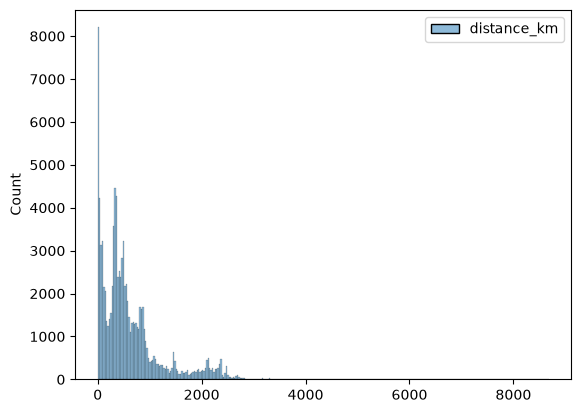

In [60]:
sns.histplot(distance)

In [61]:
con.sql("""
CREATE OR REPLACE TEMP VIEW zip_coordinates AS

SELECT 
    geolocation_zip_code_prefix AS zip_prefix,
    geolocation_state as state,
    MEDIAN(geolocation_lat) AS latitude,
    MEDIAN(geolocation_lng) AS longitude,
    MIN(geolocation_lat) AS min_lat,
    MAX(geolocation_lat) AS max_lat,
    MIN(geolocation_lng) AS min_lng,
    MAX(geolocation_lng) AS max_lng,
    AVG(geolocation_lat) AS avg_lat,
    AVG(geolocation_lng) AS avg_lng,
    (max_lat - min_lat) AS lat_diff,
    (max_lng - min_lng) AS lng_diff,
    ABS(avg_lat - latitude) lat_avg_median_diff,
    ABS(avg_lng - longitude) lng_avg_median_diff,

    COUNT(*) as count_coordinates
FROM geolocation
GROUP BY geolocation_zip_code_prefix, geolocation_state
""")

In [62]:
con.sql("""
SELECT * FROM zip_coordinates
""")

┌────────────┬─────────┬─────────────────────┬─────────────────────┬─────────────────────┬─────────────────────┬─────────────────────┬─────────────────────┬─────────────────────┬─────────────────────┬───────────────────────┬───────────────────────┬────────────────────────┬────────────────────────┬───────────────────┐
│ zip_prefix │  state  │      latitude       │      longitude      │       min_lat       │       max_lat       │       min_lng       │       max_lng       │       avg_lat       │       avg_lng       │       lat_diff        │       lng_diff        │  lat_avg_median_diff   │  lng_avg_median_diff   │ count_coordinates │
│  varchar   │ varchar │       double        │       double        │       double        │       double        │       double        │       double        │       double        │       double        │        double         │        double         │         double         │         double         │       int64       │
├────────────┼─────────┼───────────────────

In [63]:
con.sql("""
CREATE OR REPLACE TEMP VIEW route_distances AS

WITH order_sellers AS (
    SELECT 
        order_id,
        seller_id
    FROM order_items
    GROUP BY order_id, seller_id
),
order_seller_count AS (
    SELECT
        order_id,
        COUNT(seller_id) AS seller_count
    FROM order_sellers
    GROUP BY order_id
),
route_coordinates AS (
SELECT
    order_id,
    sellers.seller_id,
    customers.customer_id,
    customer_state,
    seller_state,
    seller_zip_code_prefix,
    customer_zip_code_prefix,
    seller_geo.latitude AS seller_latitude,
    seller_geo.longitude AS seller_longitude,
    customer_geo.latitude AS customer_latitude,
    customer_geo.longitude AS customer_longitude
FROM order_sellers
    JOIN orders USING (order_id)
    JOIN sellers ON order_sellers.seller_id = sellers.seller_id
    JOIN customers ON orders.customer_id = customers.customer_id
    JOIN order_seller_count osc USING (order_id)
    LEFT JOIN zip_coordinates seller_geo 
        ON seller_geo.zip_prefix = sellers.seller_zip_code_prefix
        AND seller_geo.state = sellers.seller_state
    LEFT JOIN zip_coordinates customer_geo 
        ON customer_geo.zip_prefix = customers.customer_zip_code_prefix 
        AND customer_geo.state = customers.customer_state
WHERE osc.seller_count = 1
),
coordinates_radians AS ( 
SELECT
    order_id,
    seller_id,
    customer_state,
    seller_state,
    seller_latitude,
    seller_longitude,
    customer_latitude,
    customer_longitude,
    RADIANS(seller_latitude) AS seller_lat_rad,
    RADIANS(seller_longitude) AS seller_lng_rad,
    RADIANS(customer_latitude) AS customer_lat_rad,
    RADIANS(customer_longitude) AS customer_lng_rad
FROM route_coordinates rc
WHERE (rc.seller_latitude IS NOT NULL AND rc.customer_latitude IS NOT NULL AND rc.seller_longitude IS NOT NULL AND rc.customer_longitude IS NOT NULL)
),
haversine_components AS (
SELECT
    order_id,
    seller_id,
    seller_state,
    customer_state,
    customer_lat_rad - seller_lat_rad AS delta_lat,
    customer_lng_rad - seller_lng_rad AS delta_lng,
    POW(SIN(delta_lat / 2), 2) + COS(seller_lat_rad) * COS(customer_lat_rad) * POW(SIN(delta_lng / 2), 2) AS a
FROM coordinates_radians
)
SELECT 
    order_id,
    rc.seller_id,
    rc.seller_state,
    rc.customer_state,
    seller_zip_code_prefix,
    customer_zip_code_prefix,
    seller_latitude,
    seller_longitude,
    customer_latitude,
    customer_longitude,
    6371 * 2 * ASIN(SQRT(a)) AS straight_line_distance_km
FROM haversine_components     
    JOIN route_coordinates rc USING (order_id)
""")

In [64]:
con.sql("""
SELECT COUNT(*), COUNT(DISTINCT order_id)
FROM route_distances
""")

┌──────────────┬──────────────────────────┐
│ count_star() │ count(DISTINCT order_id) │
│    int64     │          int64           │
├──────────────┼──────────────────────────┤
│        96333 │                    96333 │
└──────────────┴──────────────────────────┘

In [65]:
con.sql("""
SELECT
    QUANTILE_CONT(straight_line_distance_km, 0.8) AS p80,
    QUANTILE_CONT(straight_line_distance_km, 0.9) AS p90,
    QUANTILE_CONT(straight_line_distance_km, 0.95) AS p95,
    QUANTILE_CONT(straight_line_distance_km, 0.99) AS p99,
    QUANTILE_CONT(straight_line_distance_km, 0.999) AS p99_9,
FROM route_distances
""")

┌───────────────────┬────────────────────┬────────────────────┬────────────────────┬────────────────────┐
│        p80        │        p90         │        p95         │        p99         │       p99_9        │
│      double       │       double       │       double       │       double       │       double       │
├───────────────────┼────────────────────┼────────────────────┼────────────────────┼────────────────────┤
│ 877.4481252707185 │ 1461.9943761373859 │ 2101.2557760205873 │ 2483.5129452383767 │ 3135.5247263259726 │
└───────────────────┴────────────────────┴────────────────────┴────────────────────┴────────────────────┘

In [66]:
con.sql("""
SELECT 
    customer_state, 
    seller_state, 
    seller_zip_code_prefix, 
    customer_zip_code_prefix, 
    straight_line_distance_km,
    exc_seller.lat_diff as seller_lat_diff, 
    exc_customer.lat_diff as customer_lat_diff, 
    exc_seller.lng_diff as seller_lng_diff,
    exc_customer.lng_diff as customer_lng_diff,
FROM route_distances rc
    LEFT JOIN zip_coordinates exc_seller
        ON rc.seller_zip_code_prefix = exc_seller.zip_prefix
        AND rc.seller_state = exc_seller.state
    LEFT JOIN zip_coordinates exc_customer
        ON rc.customer_zip_code_prefix = exc_customer.zip_prefix
        AND rc.customer_state = exc_customer.state
ORDER BY straight_line_distance_km DESC
LIMIT 20;
""")

┌────────────────┬──────────────┬────────────────────────┬──────────────────────────┬───────────────────────────┬──────────────────────┬──────────────────────┬──────────────────────┬──────────────────────┐
│ customer_state │ seller_state │ seller_zip_code_prefix │ customer_zip_code_prefix │ straight_line_distance_km │   seller_lat_diff    │  customer_lat_diff   │   seller_lng_diff    │  customer_lng_diff   │
│    varchar     │   varchar    │        varchar         │         varchar          │          double           │        double        │        double        │        double        │        double        │
├────────────────┼──────────────┼────────────────────────┼──────────────────────────┼───────────────────────────┼──────────────────────┼──────────────────────┼──────────────────────┼──────────────────────┤
│ PR             │ SC           │ 89288                  │ 83252                    │         8677.859564276323 │ 0.021447870826623472 │                  0.0 │   0.031985519164

In [145]:
con.sql("""
SELECT 
    COUNT(*),
    MEDIAN(lat_diff) AS median_lat_diff,
    MEDIAN(lng_diff) AS median_lng_diff,
    QUANTILE_CONT(lat_diff, 0.9) AS lat_diff_p90,
    QUANTILE_CONT(lat_diff, 0.95) AS lat_diff_p95,
    QUANTILE_CONT(lat_diff, 0.99) AS lat_diff_p99,
    QUANTILE_CONT(lat_diff, 0.999) AS lat_diff_p999,
    QUANTILE_CONT(lng_diff, 0.9) AS lng_diff_p90,
    QUANTILE_CONT(lng_diff, 0.95) AS lng_diff_p95,
    QUANTILE_CONT(lng_diff, 0.99) AS lng_diff_p99,
    QUANTILE_CONT(lng_diff, 0.999) AS lng_diff_p999,
    MAX(lat_diff),
    MAX(lng_diff)
FROM zip_coordinates
""")

┌──────────────┬──────────────────────┬──────────────────────┬─────────────────────┬─────────────────────┬───────────────────┬────────────────────┬─────────────────────┬─────────────────────┬───────────────────┬────────────────────┬───────────────────┬───────────────────┐
│ count_star() │   median_lat_diff    │   median_lng_diff    │    lat_diff_p90     │    lat_diff_p95     │   lat_diff_p99    │   lat_diff_p999    │    lng_diff_p90     │    lng_diff_p95     │   lng_diff_p99    │   lng_diff_p999    │   max(lat_diff)   │   max(lng_diff)   │
│    int64     │        double        │        double        │       double        │       double        │      double       │       double       │       double        │       double        │      double       │       double       │      double       │      double       │
├──────────────┼──────────────────────┼──────────────────────┼─────────────────────┼─────────────────────┼───────────────────┼────────────────────┼─────────────────────┼────────────

In [68]:
con.sql("""
WITH zip_tresholds AS ( 
SELECT 
    QUANTILE_CONT(lat_diff, 0.999) AS lat_diff_p999,
    QUANTILE_CONT(lng_diff, 0.999) AS lng_diff_p999,
FROM zip_coordinates
),
zip_quality AS (
SELECT 
    zip_prefix,
    state,
    lat_diff > lat_diff_p999 AS lat_cond,
    lng_diff > lng_diff_p999 AS lng_cond
FROM zip_coordinates
    CROSS JOIN zip_tresholds
)
SELECT
    COUNT(*),
    COUNT(*) FILTER (WHERE lat_cond OR lng_cond),
    COUNT(*) FILTER (WHERE lat_cond AND lng_cond)
FROM zip_quality
""")

┌──────────────┬────────────────────────────────────────────────────┬─────────────────────────────────────────────────────┐
│ count_star() │ count_star() FILTER (WHERE (lat_cond OR lng_cond)) │ count_star() FILTER (WHERE (lat_cond AND lng_cond)) │
│    int64     │                       int64                        │                        int64                        │
├──────────────┼────────────────────────────────────────────────────┼─────────────────────────────────────────────────────┤
│        19023 │                                                 22 │                                                  18 │
└──────────────┴────────────────────────────────────────────────────┴─────────────────────────────────────────────────────┘

In [107]:
con.sql("""
WITH zip_tresholds AS ( 
SELECT 
    QUANTILE_CONT(lat_diff, 0.999) AS lat_diff_p999,
    QUANTILE_CONT(lng_diff, 0.999) AS lng_diff_p999,
FROM zip_coordinates
),
zip_quality AS (
SELECT 
    zip_prefix,
    state,
    lat_diff > lat_diff_p999 AS lat_cond,
    lng_diff > lng_diff_p999 AS lng_cond
FROM zip_coordinates
    CROSS JOIN zip_tresholds
),
route_zip_quality AS (
SELECT 
    order_id,
    seller_zip_code_prefix,
    seller_state,
    customer_zip_code_prefix,
    customer_state,
    seller_quality.lat_cond AS seller_lat_cond,
    seller_quality.lng_cond AS seller_lng_cond,
    customer_quality.lat_cond AS customer_lat_cond,
    customer_quality.lng_cond AS customer_lng_cond,

FROM route_distances rd
    JOIN zip_quality seller_quality 
        ON rd.seller_zip_code_prefix = seller_quality.zip_prefix
        AND rd.seller_state = seller_quality.state
    JOIN zip_quality customer_quality 
        ON rd.customer_zip_code_prefix = customer_quality.zip_prefix
        AND rd.customer_state = customer_quality.state
),
route_quality_summary AS ( 
SELECT
    COUNT(*) as orders_count,
    COUNT(*) FILTER (WHERE seller_lat_cond OR seller_lng_cond) AS seller_suspicious,
    COUNT(*) FILTER (WHERE customer_lat_cond OR customer_lng_cond) AS customer_suspicious,
    COUNT(*) FILTER (WHERE (seller_lat_cond OR seller_lng_cond) OR (customer_lat_cond OR customer_lng_cond)) AS route_suspicious

FROM route_zip_quality
)
SELECT route_suspicious / orders_count * 100 AS suspicious_pct FROM route_quality_summary
""")

┌─────────────────────┐
│   suspicious_pct    │
│       double        │
├─────────────────────┤
│ 0.06539815016660958 │
└─────────────────────┘

In [163]:
con.sql("""
WITH zip_tresholds AS ( 
SELECT 
    QUANTILE_CONT(lat_diff, 0.999) AS lat_diff_p999,
    QUANTILE_CONT(lng_diff, 0.999) AS lng_diff_p999,
FROM zip_coordinates
),
zip_quality AS (
SELECT 
    zip_prefix,
    state,
    lat_diff > lat_diff_p999 AS lat_cond,
    lng_diff > lng_diff_p999 AS lng_cond
FROM zip_coordinates
    CROSS JOIN zip_tresholds
),
route_zip_quality AS (
SELECT 
    order_id,
    seller_zip_code_prefix,
    seller_state,
    customer_zip_code_prefix,
    customer_state,
    straight_line_distance_km,
    seller_quality.lat_cond AS seller_lat_cond,
    seller_quality.lng_cond AS seller_lng_cond,
    customer_quality.lat_cond AS customer_lat_cond,
    customer_quality.lng_cond AS customer_lng_cond,
    (
        seller_lat_cond
        OR seller_lng_cond
        OR customer_lat_cond
        OR customer_lng_cond
    ) AS is_suspicious_route

FROM route_distances rd
    JOIN zip_quality seller_quality 
        ON rd.seller_zip_code_prefix = seller_quality.zip_prefix
        AND rd.seller_state = seller_quality.state
    JOIN zip_quality customer_quality 
        ON rd.customer_zip_code_prefix = customer_quality.zip_prefix
        AND rd.customer_state = customer_quality.state
)
SELECT 
    is_suspicious_route,
    COUNT(*),
    AVG(straight_line_distance_km),
    MEDIAN(straight_line_distance_km),
    MIN(straight_line_distance_km),
    MAX(straight_line_distance_km),
    QUANTILE_CONT(straight_line_distance_km, 0.99)
    

FROM route_zip_quality
GROUP BY is_suspicious_route
""")

┌─────────────────────┬──────────────┬────────────────────────────────┬───────────────────────────────────┬────────────────────────────────┬────────────────────────────────┬────────────────────────────────────────────────┐
│ is_suspicious_route │ count_star() │ avg(straight_line_distance_km) │ median(straight_line_distance_km) │ min(straight_line_distance_km) │ max(straight_line_distance_km) │ quantile_cont(straight_line_distance_km, 0.99) │
│       boolean       │    int64     │             double             │              double               │             double             │             double             │                     double                     │
├─────────────────────┼──────────────┼────────────────────────────────┼───────────────────────────────────┼────────────────────────────────┼────────────────────────────────┼────────────────────────────────────────────────┤
│ true                │           63 │             1068.9034463900307 │                 644.3981758095734 │ 

#### Вывод: 
63 маршрута (0,07%) связаны с ZIP-префиксами, имеющими экстремальный внутренний разброс координат. Эти маршруты в среднем длиннее остальных, однако их исключение практически не изменяет среднее, медиану и 99-й перцентиль расстояния. Максимальное расстояние остаётся аномальным, поскольку фильтр внутреннего разброса не обнаруживает согласованно ошибочные координаты. Поэтому экстремумы следует интерпретировать осторожно, тогда как основные характеристики распределения устойчивы к найденным аномалиям.

### Связь расстояния и опоздания RJ